# Check development environment

In [46]:
import torch
import torchvision
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
GPU available: False


In [47]:
# Set Random Seed

import random
import torch

SEED = 2026

random.seed(SEED)
torch.manual_seed(SEED)

# Bring the Data
Let's get the images for the AI ​​to learn from.

In [48]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor() # Convert images into Tensor

train_data = datasets.FashionMNIST(
    root = "./data",
    train = True,
    download = True,
    transform = transform
)


test_data = datasets.FashionMNIST(
    root = "./data",
    train = False,
    download = True,
    transform = transform
)

print("No.Of Training Data:", len(train_data)) # Check if train & test Data are successfully downloaded
print("No.Of Test Data:", len(test_data))

No.Of Training Data: 60000
No.Of Test Data: 10000


# Label image with its name
And select one image and display it

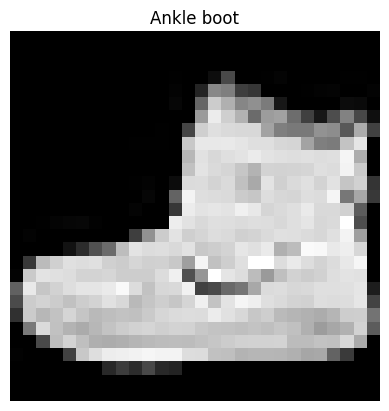

In [49]:
labels = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

image, label = train_data[0] # Choose one image to display


plt.imshow(image.squeeze(), cmap = "gray")
plt.title(labels[label])
plt.axis("off")
plt.show()

# Lets make CNN Model!
The stages above haven't trained the AI yet.

Now, here, we will train the model.

In [50]:
from torch.utils.data import DataLoader

train_loader = DataLoader(   #Pass images to the model in batches of 64
    train_data,
    batch_size = 64,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size = 64,
    shuffle = False
)

In [51]:
import torch.nn as nn
import torch.nn.functional as F

class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)  # Create a Convolutional Layer
        self.pool = nn.MaxPool2d(2, 2)    # Create a Max Pooling Layer

        self.fc1 = nn.Linear(16 * 14 * 14, 128)     # Create Fully Connected Layer
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = torch.flatten(x, start_dim = 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model = FashionCNN()

print(model)

FashionCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


# Train the AI Model!
Now, let's train the AI using the Fashion-MNIST training data.

In [52]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss() # Define the loss function

optimizer = optim.Adam(model.parameters(), lr=0.001) # Use Adam Optimiser

In [53]:
num_epochs = 5

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for images, labels_batch in train_loader:
        optimizer.zero_grad() # Clear previous gradients

        outputs = model(images) # Make predictions using the images

        loss = criterion(outputs, labels_batch) # Calculate prediction errors

        loss.backward() # Calculate graditents through back propagation

        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)  # Calculate average loss

    print(
        f"Epoch [{epoch + 1}/{num_epochs}], "
        f"Loss: {average_loss:.4f}"
    )

Epoch [1/5], Loss: 0.4608
Epoch [2/5], Loss: 0.3037
Epoch [3/5], Loss: 0.2591
Epoch [4/5], Loss: 0.2280
Epoch [5/5], Loss: 0.2042


# Test the AI Model
Now that AI has finished trainging, let's see how accurately it can classify unseen image!

In [54]:
correct = 0
total = 0

model.eval()

with torch.no_grad():    # Disable gradient calculation during testing
    for images, labels_batch in test_loader:
        outputs = model(images)

        _, predicted = torch.max(outputs, 1)  # Get the prediction class

        total += labels_batch.size(0)  # Count the total number of images
        correct += (predicted == labels_batch).sum().item() # Count correct predictions

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")
print(f"No.Of Correct Answer: {correct} / {total}")

Test Accuracy: 90.60%
No.Of Correct Answer: 9060 / 10000


# Make a Prediction
Let's select one image from the test dataset and see what the AI predicts.

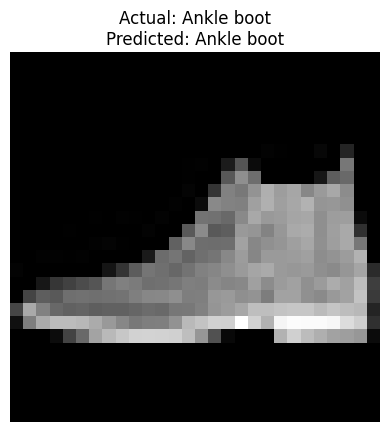

Actual Answer: Ankle boot
AI Predicted: Ankle boot


In [55]:
import matplotlib.pyplot as plt

image, true_label = test_data[0]

image_batch = image.unsqueeze(0)

model.eval()

with torch.no_grad():
    output = model(image_batch)
    predicted_label = output.argmax(dim=1).item() # Select the class with the highest score

#Display the image with its actual and predicted labels
plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Actual: {labels[true_label]}\n"
    f"Predicted: {labels[predicted_label]}"
)
plt.axis("off")
plt.show()

print("Actual Answer:", labels[true_label])
print("AI Predicted:", labels[predicted_label])

# Check Multiple Prediction
Let's display 10 images at once and compare the predictions with their actual labels

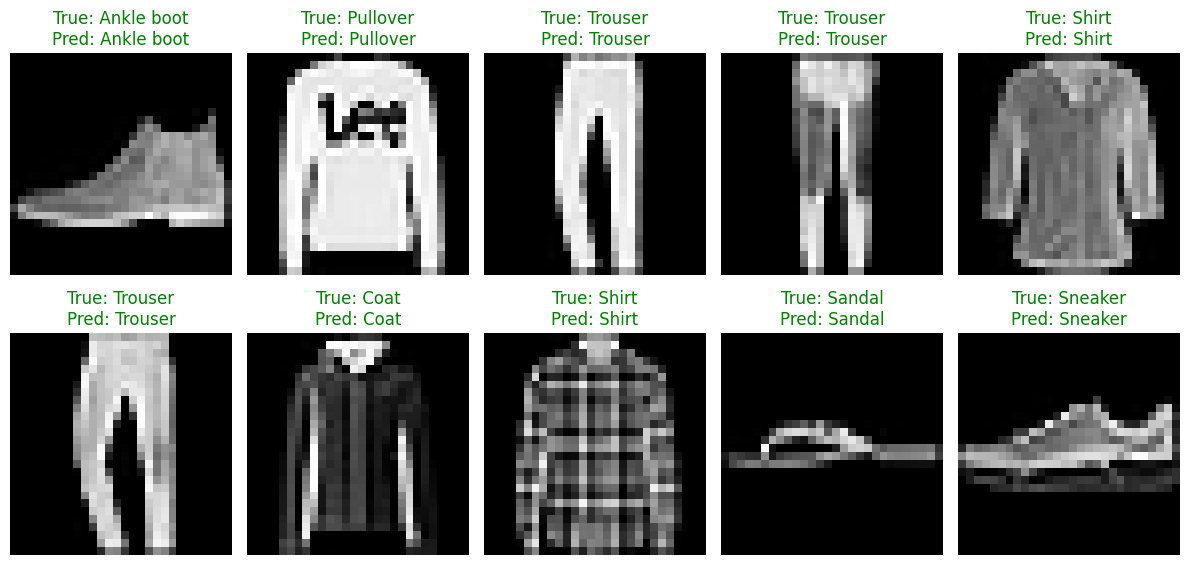

In [56]:
fig, axes = plt.subplots(2, 5, figsize = (12, 6))

model.eval()

with torch.no_grad():
    for i, ax in enumerate(axes.flat):
        image, true_label = test_data[i]

        output = model(image.unsqueeze(0))
        predicted_label = output.argmax(dim = 1).item()

        # Green means correct prediction, red means incorrect
        ax.imshow(image.squeeze(), cmap = "gray")
        ax.set_title(
            f"True: {labels[true_label]}\n"
            f"Pred: {labels[predicted_label]}",
            color="green" if predicted_label == true_label else "red"
        )
        ax.axis("off")

plt.tight_layout() # Adjust spacing between images
plt.show()

# Visualise the Test Results
Let's create a bar chart to compare the number of correct and incorrect predictions.

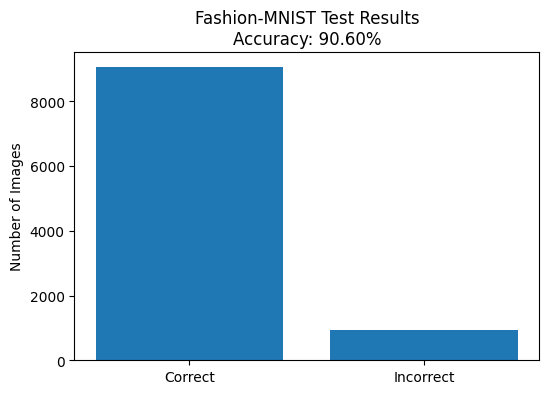

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.bar(
    ["Correct", "Incorrect"],
    [correct, total - correct]
)

plt.title(f"Fashion-MNIST Test Results\nAccuracy: {accuracy:.2f}%")
plt.ylabel("Number of Images")
plt.show()

# Find Incorrect Predictions!
Let's find images that the AI classified incorrectly and display up to 10 of them.

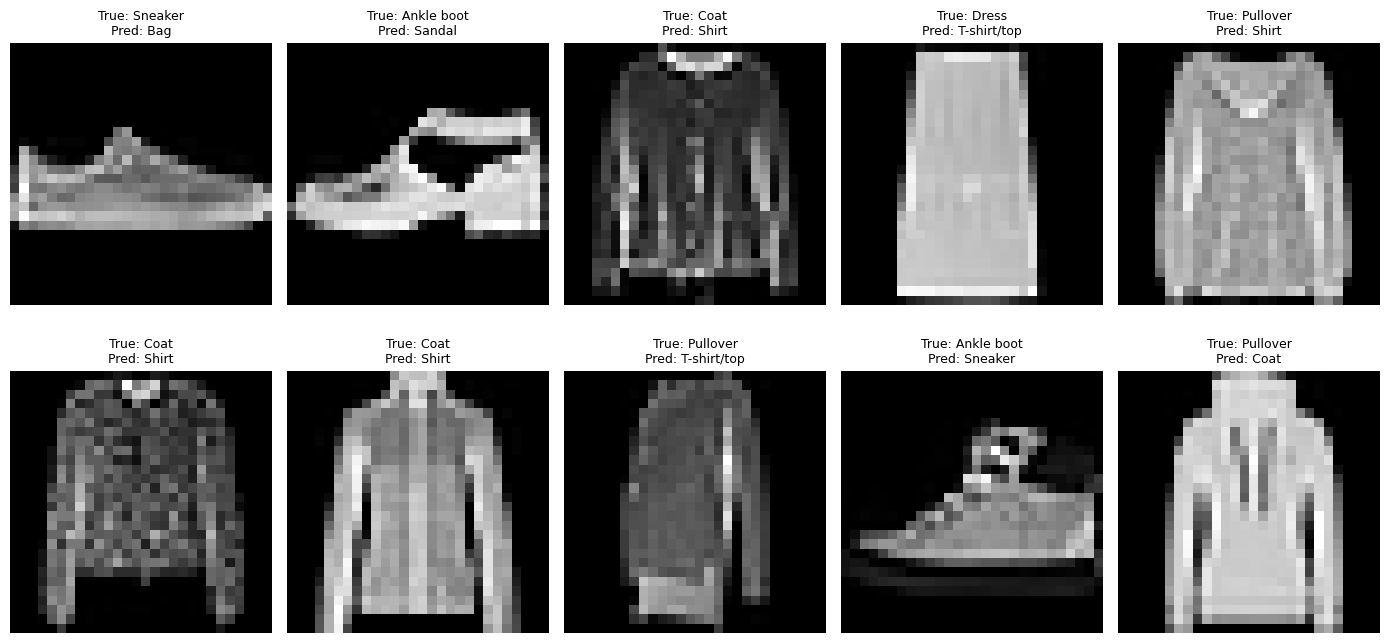

In [58]:

import matplotlib.pyplot as plt
import torch

labels = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

model.eval()

wrong_images = []
wrong_labels = []
wrong_preds = []

with torch.no_grad():
    for images, batch_labels in test_loader:

        outputs = model(images)
        predictions = outputs.argmax(dim = 1)

        # Find the indices of incorrectly classified image
        wrong_indices = (predictions != batch_labels).nonzero(
            as_tuple=True
        )[0]

        for i in wrong_indices:
            wrong_images.append(images[i].cpu().squeeze()) # Store the image
            wrong_labels.append(batch_labels[i].item())  # Store the actual label
            wrong_preds.append(predictions[i].item())   # Store the predicted label

            if len(wrong_images) >= 10:
                break

        if len(wrong_images) >= 10:
            break

#Display the results
if len(wrong_images) == 0:
    print("No wrong prediction!!")
else:
    fig, axes = plt.subplots(2, 5, figsize = (14, 7))

    for i, ax in enumerate(axes.flat):
        if i < len(wrong_images):
            ax.imshow(wrong_images[i], cmap="gray")
            # Compare the actual lable with the predicted label
            ax.set_title(
                f"True: {labels[wrong_labels[i]]}\n"
                f"Pred: {labels[wrong_preds[i]]}",
                fontsize = 9
            )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
